# 05bis. 3D Soneira-Peebles model of the fruit fly

**Question.** Can a 3D SP mixture reproduce the 2PCF of the fly neurons measured in
notebook 05 (γ = 1.02 ± 0.04, r₀ ≈ 20 µm, D = 1.98)? What does it miss?

**Data.** Pickle `out/fly/fly_2pcf_*` of notebook 05 and `data/fly_neuron_net/neurons.zip`.
**Outputs.** `out/05bis_fly_sp3d.csv`, `out/05bis_fly_sp3d_scan.csv`, `out/fly/fly_sp3d_*`.
**Paper.** Not in the current version.
**Code.** End of `src/sp_helpers.py` (`lambda_of_gamma`, `sample_in_ball`,
`inside_hull`, `soneira_peebles_nd`).

The SP model was first written in 3D for galaxies. The 2D code of the repository
needs six changes to run in 3D.

| 2D code | effect in 3D | here |
|---|---|---|
| `l = eta**(1/(2-gamma))` | D off by one (0.98 instead of 1.98) | `lambda_of_gamma(eta, gamma, dim=3)` |
| children in a disc | flat cloud | `sample_in_ball` |
| `r = R·u` | not uniform in the ball (density ∝ r^(1−d)) | `r = R·u^(1/d)` (section 4) |
| `check_inside` redraws the whole tree | never ends at η^L ~ 10⁵ | rejection child by child |
| `L = int(log(N)/log(eta))` | ties the range of the power law to N | L set by the range (section 5) |
| `fit_2pcf` bounded at γ ≤ 1.95 | 2D bound | bound at `dim` |

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, cKDTree
from scipy.optimize import curve_fit

ROOT = Path.cwd().resolve().parent.parent           # repository root
sys.path.insert(0, str(ROOT / "src"))
import methods_two_point_correlation as mtpc
import save_load_pickle as slp
import sp_helpers as sph

# Okabe-Ito palette, consistent with notebooks 01-06
C = {"data": "#000000", "fly": "#0072B2", "sp": "#D55E00", "mix": "#009E73",
     "random": "#999999", "warn": "#CC79A7", "alt": "#56B4E9"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "axes.axisbelow": True})

SEED  = 42
NM    = 1e3                                  # 1 µm = 1000 nm
CACHE = ROOT / "out" / "05bis_cache"
CACHE.mkdir(parents=True, exist_ok=True)
print("cache:", CACHE)

cache: out/05bis_cache


## 1. Inputs from notebook 05

γ = 1.022, r₀ = 19.5 µm, N = 238 909, candidate η = 2, 3, 5, 4, 6 (silhouette), and the
439 vertices of the 3D convex hull (`hull_points`), used as the domain.

In [2]:
PKL = ROOT / "out" / "fly" / "fly_2pcf_4_20000_8_20000_21"
d   = slp.load_results(PKL)

hull          = ConvexHull(d["hull_points"])
gamma_d, r0_d = d["fit_SP"]
N             = d["number_points"]
r_edges, r_c  = d["r_edges"], d["r_centers"]
xi_data, err_data = d["xi"].mean(axis=0), d["xi"].std(axis=0)
l_cluster     = d["clustering"]
prm           = d["params"]
rmin_d, rmax_d = prm["rmin"], prm["rmax"]
Nr_prime, N_run, Nsample = prm["Nr_prime"], prm["N_run"], prm["Nsample"]

print(f"dim = {d['dim']}  |  N = {N:,} points  |  γ = {gamma_d:.3f}  |  "
      f"r0 = {r0_d/NM:.1f} µm".replace(",", " "))
print(f"domain: 3D convex hull, {len(hull.vertices)} vertices, "
      f"V = {hull.volume/NM**3:.3e} µm³")
print(f"bins: {len(r_c)} from {rmin_d/NM:.2f} to {rmax_d/NM:.0f} µm (log)")
print(f"candidate η (silhouette, decreasing): {l_cluster}")

dim = 3  |  N = 238 909 points  |  γ = 1.022  |  r0 = 19.5 µm
domain: 3D convex hull, 439 vertices, V = 3.930e+07 µm³
bins: 20 from 1.96 to 331 µm (log)
candidate η (silhouette, decreasing): [2, 3, 5, 4, 6]


## 2. Model and domain

Each point of level i generates η children uniformly in the ball of radius R/λ^i. The
η^L leaves form the cloud. D = ln η / ln λ, hence λ = η^(1/(3−γ)).

The power law only holds between R/λ^(L−1) and R. So R must cover the domain, and
R/λ^(L−1) must be below the first measured bin (2.2 µm).

R is the circumscribed radius of the hull, around the centroid of its vertices.
Children outside the hull are rejected, so level 1 is a uniform draw in the hull. The
hierarchy only structures the cloud below the size of the brain.

In [3]:
cen    = d["hull_points"].mean(axis=0)                            # centroid of the vertices
R_ref  = float(np.linalg.norm(hull.points - cen, axis=1).max())   # circumscribed radius
extent = hull.points.max(axis=0) - hull.points.min(axis=0)

print(f"seed  : centroid of the vertices, {np.round(cen/NM, 1)} µm")
print(f"R_ref : {R_ref/NM:.1f} µm  (the level-0 ball contains the whole hull, "
      f"by construction)")
print(f"        V_ball / V_hull = {4/3*np.pi*R_ref**3/hull.volume:.1f} → "
      f"{100*(1 - hull.volume/(4/3*np.pi*R_ref**3)):.0f} % of the level-1 children "
      f"fall outside and are drawn again")
print(f"extent of the domain: {np.round(extent/NM, 0)} µm")

print(f"\nλ for each candidate η (γ = {gamma_d:.3f}):")
print(f"{'η':>4}{'λ (3D)':>10}{'λ (2D formula)':>17}{'D = lnη/lnλ':>14}"
      f"{'D if 2 is kept':>20}")
for eta in l_cluster:
    l3 = sph.lambda_of_gamma(eta, gamma_d, 3)
    l2 = sph.lambda_of_gamma(eta, gamma_d, 2)
    print(f"{eta:>4}{l3:>10.4f}{l2:>17.4f}{np.log(eta)/np.log(l3):>14.3f}"
          f"{np.log(eta)/np.log(l2):>20.3f}")

seed  : centroid of the vertices, [544.1 236.4 157.2] µm
R_ref : 485.6 µm  (the level-0 ball contains the whole hull, by construction)
        V_ball / V_hull = 12.2 → 92 % of the level-1 children fall outside and are drawn again
extent of the domain: [815. 392. 278.] µm

λ for each candidate η (γ = 1.022):
   η    λ (3D)   λ (2D formula)   D = lnη/lnλ      D if 2 is kept
   2    1.4198           2.0321         1.978               0.978
   3    1.7429           3.0767         1.978               0.978
   5    2.2566           5.1885         1.978               0.978
   4    2.0158           4.1295         1.978               0.978
   6    2.4746           6.2523         1.978               0.978


### First levels of a tree (η = 5)

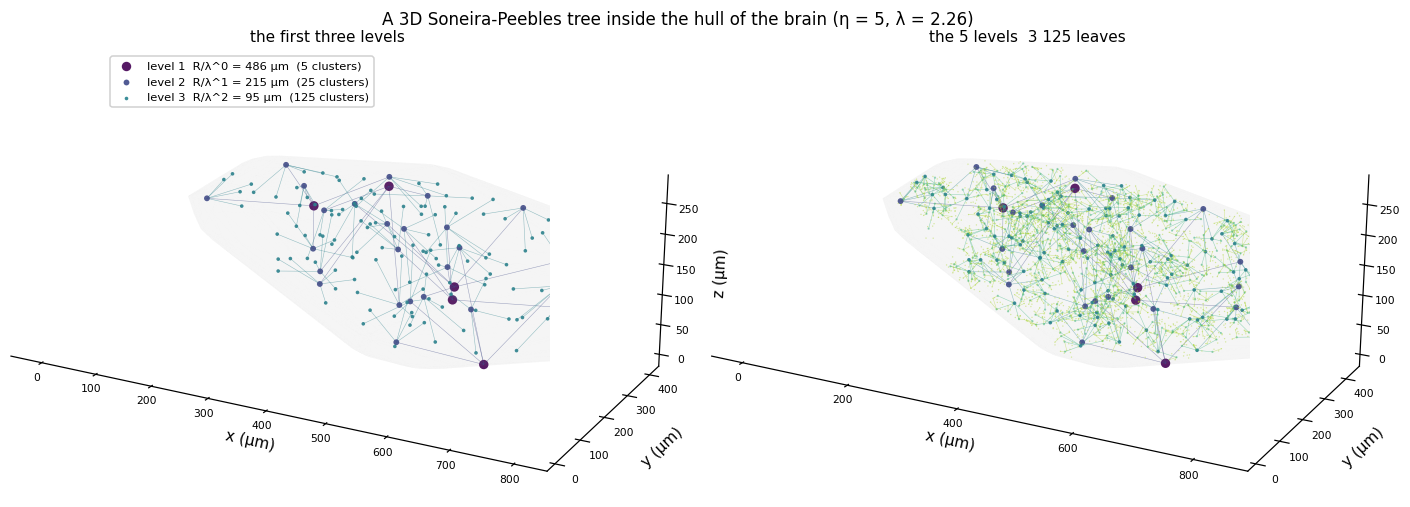

In [4]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

rng_v = np.random.default_rng(SEED + 1)      # stream dedicated to display
eta_v, L_v = 5, 5
lam_v = sph.lambda_of_gamma(eta_v, gamma_d, 3)
_, LV = sph.soneira_peebles_nd(eta_v, lam_v, L_v, R_ref, cen, hull=hull,
                               rng=rng_v, return_levels=True)

def view_3d(ax, zoom=1.5):
    ax.set_box_aspect(extent, zoom=zoom)
    ax.set_xlabel("x (µm)", labelpad=-6); ax.set_ylabel("y (µm)", labelpad=-6)
    ax.set_zlabel("z (µm)", labelpad=-8)
    ax.tick_params(labelsize=7, pad=-3); ax.grid(False)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_alpha(0)
    ax.view_init(elev=20, azim=-62)

V = hull.points / NM
fig = plt.figure(figsize=(13, 4.6))
for k, upto in enumerate([3, L_v]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.add_collection3d(Poly3DCollection([V[s] for s in hull.simplices],
                                         facecolor="0.55", alpha=.04, edgecolor="none"))
    cols = plt.cm.viridis(np.linspace(0, .88, L_v))
    for i in range(upto):
        P = LV[i][0] / NM
        if i > 0:                                     # parent -> child segments
            Q = LV[i - 1][0][LV[i][1]] / NM
            seg = np.stack([P, Q], axis=1)
            idx = rng_v.choice(len(seg), min(len(seg), 900), replace=False)
            for a, b in seg[idx]:
                ax.plot(*np.stack([a, b], axis=1), color=cols[i], lw=.35, alpha=.5)
        ax.scatter(*P.T, color=cols[i], s=max(38 / (2.6 ** i), .35),
                   alpha=.9 if i < 3 else .45, lw=0,
                   label=f"level {i+1}, R/λ^{i} = {R_ref/lam_v**i/NM:.0f} µm  "
                         f"({len(P):,} clusters)".replace(",", " "))
    ax.set_title(("the first three levels" if upto == 3 else
                  f"the {L_v} levels, {len(LV[-1][0]):,} leaves").replace(",", " "),
                 fontsize=10)
    view_3d(ax)
    if upto == 3:
        ax.legend(fontsize=7.5, loc="upper left", framealpha=.9)
fig.suptitle(f"A 3D Soneira-Peebles tree inside the hull of the brain "
             f"(η = {eta_v}, λ = {lam_v:.2f})", fontsize=11)
fig.subplots_adjust(left=.01, right=.99, top=.90, bottom=.02, wspace=0)
plt.show()

## 3. Check of λ = η^(1/(3−γ)) without domain

On the bare tree, the correlation dimension is the slope of the number of pairs closer
than r, N_pairs(<r) ∝ r^D, fitted between 3 R/λ^(L−1) and 0.3 R. No domain, random
catalogue or power-law fit is involved.

In [5]:
def D_pair_count(P, lo, hi, nsub=25000, seed=0, nbins=25):
    """Correlation dimension from pair counts, log-log slope of N(<r). No domain
    and no random catalogue, see section 6 of notebook 05."""
    g = np.random.default_rng(seed)
    P = P[g.choice(len(P), nsub, replace=False)] if len(P) > nsub else P
    re  = np.logspace(np.log10(lo), np.log10(hi), nbins)
    cum = cKDTree(P).count_neighbors(cKDTree(P), re).astype(float) - len(P)
    m   = cum > 0
    return float(np.polyfit(np.log(re[m]), np.log(cum[m]), 1)[0]), re, cum

_c = CACHE / f"free_sp_{SEED}.joblib"
if _c.exists():
    FREE = joblib.load(_c)
else:
    t0, FREE = time.time(), {}
    for eta in l_cluster:
        lam = sph.lambda_of_gamma(eta, gamma_d, 3)
        L   = int(np.ceil(np.log(R_ref / rmin_d) / np.log(lam))) + 1
        while eta ** L > 600_000 and L > 2:      # bare tree: 6e5 leaves are enough
            L -= 1
        P = sph.soneira_peebles_nd(eta, lam, L, R_ref, cen, hull=None,
                                   rng=np.random.default_rng(SEED + eta))
        r_bot = R_ref / lam ** (L - 1)
        D, re, cum = D_pair_count(P, 3 * r_bot, 0.3 * R_ref)
        FREE[eta] = dict(lamb=lam, L=L, n=len(P), r_bot=r_bot, D=D, re=re, cum=cum)
    joblib.dump(FREE, _c)
    print(f"(computed in {time.time()-t0:.0f} s)")

print(f"target dimension: D = 3 − γ = {3-gamma_d:.3f}\n")
print(f"{'η':>4}{'λ':>9}{'L':>4}{'leaves':>11}{'R/λ^(L-1)':>12}{'measured D':>12}"
      f"{'gap':>9}")
for eta, v in FREE.items():
    print(f"{eta:>4}{v['lamb']:>9.4f}{v['L']:>4}{v['n']:>11,}{v['r_bot']/NM:>12.2f}"
          f"{v['D']:>12.3f}{v['D']-(3-gamma_d):>9.3f}".replace(",", " "))
print(f"\nmean: {np.mean([v['D'] for v in FREE.values()]):.3f} "
      f"(target {3-gamma_d:.3f})")

target dimension: D = 3 − γ = 1.978

   η        λ   L     leaves   R/λ^(L-1)  measured D      gap
   2   1.4198  17    131 072        1.78       1.903   -0.075
   3   1.7429  11    177 147        1.88       1.894   -0.084
   5   2.2566   8    390 625        1.63       1.963   -0.015
   4   2.0158   9    262 144        1.78       1.978    0.000
   6   2.4746   7    279 936        2.11       1.919   -0.059

mean: 1.931 (target 1.978)


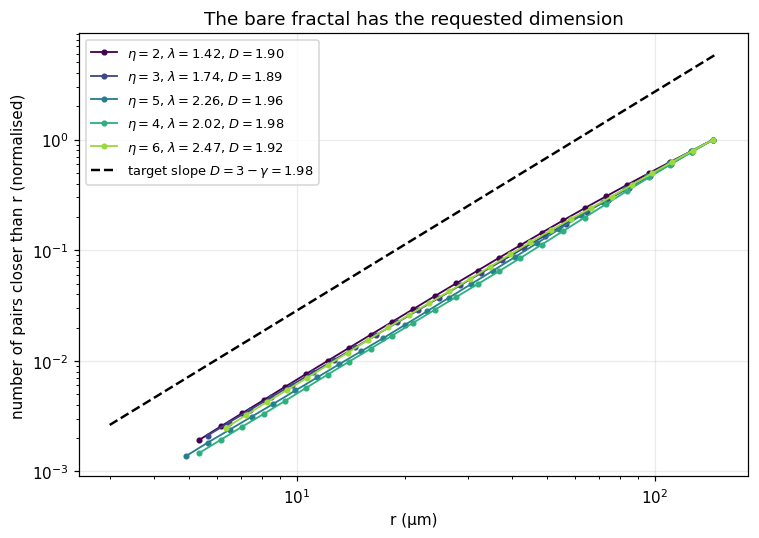

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
cols = plt.cm.viridis(np.linspace(0, .85, len(FREE)))
for (eta, v), col in zip(FREE.items(), cols):
    m = v["cum"] > 0
    ax.plot(v["re"][m]/NM, v["cum"][m]/v["cum"][m][-1], "o-", ms=3, color=col, lw=1.2,
            label=fr"$\eta={eta}$, $\lambda={v['lamb']:.2f}$, $D={v['D']:.2f}$")
rr = np.logspace(np.log10(3*NM), np.log10(150*NM), 20)
ax.plot(rr/NM, 3e-4*(rr/NM)**(3-gamma_d), "k--", lw=1.6,
        label=fr"target slope $D=3-\gamma={3-gamma_d:.2f}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel("number of pairs closer than r (normalised)")
ax.set_title("The bare fractal has the requested dimension")
ax.legend(fontsize=8.5)
fig.tight_layout(); plt.show()

## 4. Estimator and radial law

Same estimator as notebook 05. The random catalogues depend only on the domain, so
they are shared between data and models (same RR on both sides, the hull bias
cancels). The fit window is the one of the data (2.2 to 135 µm).

In [7]:
# Shared random catalogues, they only depend on the domain.
rng  = np.random.default_rng(SEED)
CATS = [mtpc.sample_in_hull(hull, Nr_prime, rng) for _ in range(N_run)]
RR   = sum(mtpc.pair_counts(c, r_edges) for c in CATS)

def xi_nd(pts, k=3, rng=rng):
    """Landy-Szalay 2PCF (Keihänen 2019), the estimator of notebook 05, except that
    the random catalogues are the ones computed above."""
    out = []
    for _ in range(k):
        sub = pts if len(pts) <= Nsample else \
              pts[rng.choice(len(pts), Nsample, replace=False)]
        DD  = mtpc.pair_counts(sub, r_edges)
        DR  = sum(mtpc.pair_counts(sub, r_edges, B=c) for c in CATS)
        out.append(mtpc.compute_LS_correlation_2019(DD, DR, RR, len(sub),
                                                    Nr_prime, Nr_prime * N_run))
    return np.array(out)

def power_law(r, gamma, r0):
    return (r / r0) ** (-gamma)

FIT_HI = 135.0 * NM
WIN    = (r_c >= r_c[0] * 0.999) & (r_c <= FIT_HI * 1.001)

def fit_pl(xi, err, dim=3):
    """Power-law fit bounded by the dimension (see notebook 05, section 5, do not
    reuse sp_helpers.fit_2pcf, which is bounded at 1.95 for the plane)."""
    m = WIN & (xi > 0)
    popt, pcov = curve_fit(power_law, r_c[m], xi[m],
                           sigma=np.maximum(err[m], 0.02 * xi[m]),
                           p0=[1.0, r_c[m][0]], bounds=([1e-3, 1.0], [dim, 1e9]),
                           maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    return dict(gamma=popt[0], r0=popt[1], gamma_err=perr[0], r0_err=perr[1],
                nbins=int(m.sum()))

f_data = fit_pl(xi_data, err_data)
print(f"check: the fit redone here on the data gives "
      f"γ = {f_data['gamma']:.3f} ± {f_data['gamma_err']:.3f}, "
      f"r0 = {f_data['r0']/NM:.1f} µm on {f_data['nbins']} bins "
      f"({r_c[WIN][0]/NM:.1f} → {r_c[WIN][-1]/NM:.0f} µm)")

check: the fit redone here on the data gives γ = 1.022 ± 0.036, r0 = 19.5 µm on 17 bins (2.2 → 135 µm)


### Radial law

`r = R·u` concentrates the children at the centre of each ball. Soneira and Peebles
use a uniform draw in the sphere, r = R·u^(1/3). The radial law should not change D
but should change the amplitude of ξ at small r. The next cell compares the two.

In [8]:
_c = CACHE / f"radial_{SEED}.joblib"
if _c.exists():
    RAD = joblib.load(_c)
else:
    t0, RAD = time.time(), {}
    eta_r = 5
    lam_r = sph.lambda_of_gamma(eta_r, gamma_d, 3)
    L_r   = int(np.ceil(np.log(R_ref / rmin_d) / np.log(lam_r))) + 1
    for law in ("uniform", "linear"):
        g = np.random.default_rng(SEED + 7)          # same seed for both
        free = sph.soneira_peebles_nd(eta_r, lam_r, L_r, R_ref, cen, hull=None,
                                      rng=g, radial=law)
        g = np.random.default_rng(SEED + 7)
        inside = sph.soneira_peebles_nd(eta_r, lam_r, L_r, R_ref, cen, hull=hull,
                                        rng=g, radial=law)
        l = xi_nd(inside, k=3, rng=g); xi_r = l.mean(axis=0)
        RAD[law] = dict(D=D_pair_count(free, 3 * R_ref / lam_r ** (L_r - 1),
                                       0.3 * R_ref)[0],
                        xi=xi_r, fit=fit_pl(xi_r, l.std(axis=0)),
                        eta=eta_r, lamb=lam_r, L=L_r, n=len(inside))
    joblib.dump(RAD, _c)
    print(f"(computed in {time.time()-t0:.0f} s)")

print(f"η = {RAD['uniform']['eta']}, λ = {RAD['uniform']['lamb']:.3f}, "
      f"L = {RAD['uniform']['L']}, only the radial law changes\n")
print(f"{'radial law':<32}{'D (bare tree)':>14}{'γ (in the domain)':>22}"
      f"{'ξ(2.2 µm)':>12}{'ξ(17 µm)':>11}")
for law, txt in [("uniform", "r = R·u^(1/3)  (Soneira-Peebles)"),
                 ("linear",  "r = R·u        (2D code)")]:
    v = RAD[law]
    print(f"{txt:<32}{v['D']:>14.3f}{v['fit']['gamma']:>22.3f}"
          f"{v['xi'][0]:>12.2f}{v['xi'][8]:>11.2f}")
print(f"{'data':<32}{'-':>14}{gamma_d:>22.3f}{xi_data[0]:>12.2f}{xi_data[8]:>11.2f}")

η = 5, λ = 2.257, L = 8, only the radial law changes

radial law                       D (bare tree)     γ (in the domain)   ξ(2.2 µm)   ξ(17 µm)
r = R·u^(1/3)  (Soneira-Peebles)         1.978                 0.919       12.55       1.90
r = R·u        (2D code)                 1.974                 0.921       27.27       4.56
data                                         -                 1.022       11.05       1.06


## 5. Depth L

ξ does not change under random thinning, so L is chosen for the range and the cloud is
then thinned to N points. Constraints, in this order: R/λ^(L−1) ≤ rmin = 2.0 µm, then
η^L ≥ N, with a cap of 2·10⁶ leaves.

In [9]:
def depth(eta, lamb, n_target, n_max=2_000_000):
    """L: (1) R/λ^(L-1) below rmin, (2) at least n_target leaves, (3) cap."""
    L_bot = int(np.ceil(np.log(R_ref / rmin_d) / np.log(lamb))) + 1   # range
    L_num = int(np.ceil(np.log(n_target) / np.log(eta)))              # size
    L = max(L_bot, L_num)
    while eta ** L > n_max and L > 2:
        L -= 1
    return L, L_bot, L_num

print(f"{'η':>4}{'λ':>9}{'L (range)':>12}{'L (size)':>14}{'L kept':>10}"
      f"{'leaves':>12}{'R/λ^(L-1)':>12}{'range λ^(L-1)':>16}")
for eta in l_cluster:
    lam = sph.lambda_of_gamma(eta, gamma_d, 3)
    L, L_bot, L_num = depth(eta, lam, N)
    print(f"{eta:>4}{lam:>9.4f}{L_bot:>12}{L_num:>14}{L:>10}{eta**L:>12,}"
          f"{R_ref/lam**(L-1)/NM:>12.2f}{lam**(L-1):>16.0f}".replace(",", " "))
print(f"\nrmin of the data = {rmin_d/NM:.2f} µm, the measured power law "
      f"covers {r_c[WIN][0]/NM:.1f} → {r_c[WIN][-1]/NM:.0f} µm, "
      f"a factor {r_c[WIN][-1]/r_c[WIN][0]:.0f}.")

   η        λ   L (range)      L (size)    L kept      leaves   R/λ^(L-1)   range λ^(L-1)
   2   1.4198          17            18        18     262 144        1.25             387
   3   1.7429          11            12        12     531 441        1.08             451
   5   2.2566           8             8         8     390 625        1.63             298
   4   2.0158           9             9         9     262 144        1.78             273
   6   2.4746           8             7         8   1 679 616        0.85             568

rmin of the data = 1.96 µm, the measured power law covers 2.2 → 135 µm, a factor 60.


## 6. Random background and scan over η

With n_SP fractal points among N, only fractal pairs are correlated, so
ξ_mix = f² ξ_SP with f = n_SP/N. We measure ρ = ⟨ξ_data/ξ_SP⟩ on the fit window and set
f = √ρ, which is `n_rand = m_SP (1/√ρ − 1)` of `sp_helpers`.

For each η, three independent trees. The cost is the RMS gap in log between ξ_mix and
ξ_data on the fit window (ξ varies by a factor 140 there, a linear gap would only see
the first bins).

In [10]:
def build_sp(eta, rng, n_target=N):
    """Full tree inside the domain, with the model parameters."""
    lam = sph.lambda_of_gamma(eta, gamma_d, 3)
    L, _, _ = depth(eta, lam, n_target)
    return sph.soneira_peebles_nd(eta, lam, L, R_ref, cen, hull=hull, rng=rng), lam, L

def calibrate(xi_sp):
    """ρ = <ξ_data/ξ_SP> on the fit window → fractal fraction f = √ρ."""
    sel = WIN & (xi_sp > 0) & (xi_data > 0)
    rho = float(np.mean(xi_data[sel] / xi_sp[sel]))
    return rho, float(min(np.sqrt(rho), 1.0))

def build_mixture(S, frac, rng, n_target=N):
    """n_SP fractal points (drawn at random) + the uniform complement."""
    n_sp = min(int(round(frac * n_target)), len(S))
    n_rd = n_target - n_sp
    M    = S[rng.choice(len(S), n_sp, replace=False)]
    if n_rd > 0:
        M = np.vstack([M, mtpc.sample_in_hull(hull, n_rd, rng)])
    return M, n_sp, n_rd

N_TRY = 3                       # independent trees per η
_c = CACHE / f"scan3_{SEED}.joblib"
if _c.exists():
    SCAN = joblib.load(_c)
    print("scan: loaded from cache")
else:
    t0, SCAN = time.time(), {}
    for eta in l_cluster:
        for t in range(N_TRY):
            g = np.random.default_rng(SEED + 1000 * t + eta)
            S, lam, L = build_sp(eta, g)
            l_sp = xi_nd(S, k=3, rng=g); xi_sp = l_sp.mean(axis=0)
            f_sp = fit_pl(xi_sp, l_sp.std(axis=0))
            rho, frac = calibrate(xi_sp)
            M, n_sp, n_rd = build_mixture(S, frac, g)
            l_mx = xi_nd(M, k=3, rng=g); xi_mx = l_mx.mean(axis=0)
            f_mx = fit_pl(xi_mx, l_mx.std(axis=0))
            s2   = WIN & (xi_mx > 0) & (xi_data > 0)
            SCAN[(eta, t)] = dict(
                lamb=lam, L=L, n_leaves=len(S), r_bot=R_ref / lam ** (L - 1),
                xi_sp=xi_sp, xi_sp_std=l_sp.std(axis=0), gamma_sp=f_sp["gamma"],
                gamma_sp_err=f_sp["gamma_err"], r0_sp=f_sp["r0"],
                rho=rho, frac=frac, N_sp=n_sp, N_rd=n_rd,
                xi_mx=xi_mx, xi_mx_std=l_mx.std(axis=0), gamma_mx=f_mx["gamma"],
                gamma_mx_err=f_mx["gamma_err"], r0_mx=f_mx["r0"],
                cost=float(np.sqrt(np.mean(np.log10(xi_mx[s2] / xi_data[s2]) ** 2))),
                cost_eucl=float(np.linalg.norm(xi_mx[WIN] - xi_data[WIN])))
    joblib.dump(SCAN, _c)
    print(f"(scan: {len(l_cluster)*N_TRY} models in {time.time()-t0:.0f} s)")

def agg(eta, key):
    v = [SCAN[(eta, t)][key] for t in range(N_TRY)]
    return float(np.mean(v)), float(np.std(v))

print(f"\n{'η':>3}{'λ':>7}{'L':>4}{'leaves':>10}{'γ_SP':>15}{'ρ':>15}"
      f"{'f':>7}{'n_rand':>9}{'γ_mix':>15}{'r0_mix':>9}{'cost':>15}")
for eta in l_cluster:
    v = SCAN[(eta, 0)]
    g_sp, g_mx, rh, fr, r0m, co = (agg(eta, k) for k in
                                   ("gamma_sp", "gamma_mx", "rho", "frac", "r0_mx", "cost"))
    print(f"{eta:>3}{v['lamb']:>7.3f}{v['L']:>4}{v['n_leaves']:>10,}"
          f"{g_sp[0]:>9.3f}±{g_sp[1]:.3f}{rh[0]:>9.3f}±{rh[1]:.3f}{fr[0]:>7.3f}"
          f"{int(round((1-fr[0])*N)):>9,}{g_mx[0]:>9.3f}±{g_mx[1]:.3f}"
          f"{r0m[0]/NM:>9.1f}{co[0]:>9.4f}±{co[1]:.4f}".replace(",", " "))
print(f"\n{'data':>3}{'':>7}{'':>4}{'':>10}{gamma_d:>9.3f}±{f_data['gamma_err']:.3f}"
      f"{'':>16}{'':>7}{'':>9}{'':>16}{r0_d/NM:>9.1f}")

scan: loaded from cache

  η      λ   L    leaves           γ_SP              ρ      f   n_rand          γ_mix   r0_mix           cost
  2  1.420  18   262 144    1.146±0.253    0.925±0.328  0.890   26 276    1.116±0.265     19.3   0.1674±0.0791
  3  1.743  12   531 441    1.043±0.081    0.674±0.050  0.821   42 855    1.004±0.046     19.9   0.0636±0.0128
  5  2.257   8   390 625    1.170±0.132    0.922±0.163  0.945   13 254    1.122±0.102     20.2   0.1167±0.0309
  4  2.016   9   262 144    1.179±0.089    0.939±0.118  0.952   11 431    1.207±0.133     19.0   0.1401±0.0485
  6  2.475   8 1 679 616    0.999±0.051    0.753±0.059  0.867   31 707    1.045±0.118     19.4   0.2080±0.1850

data                         1.022±0.036                                                     19.5


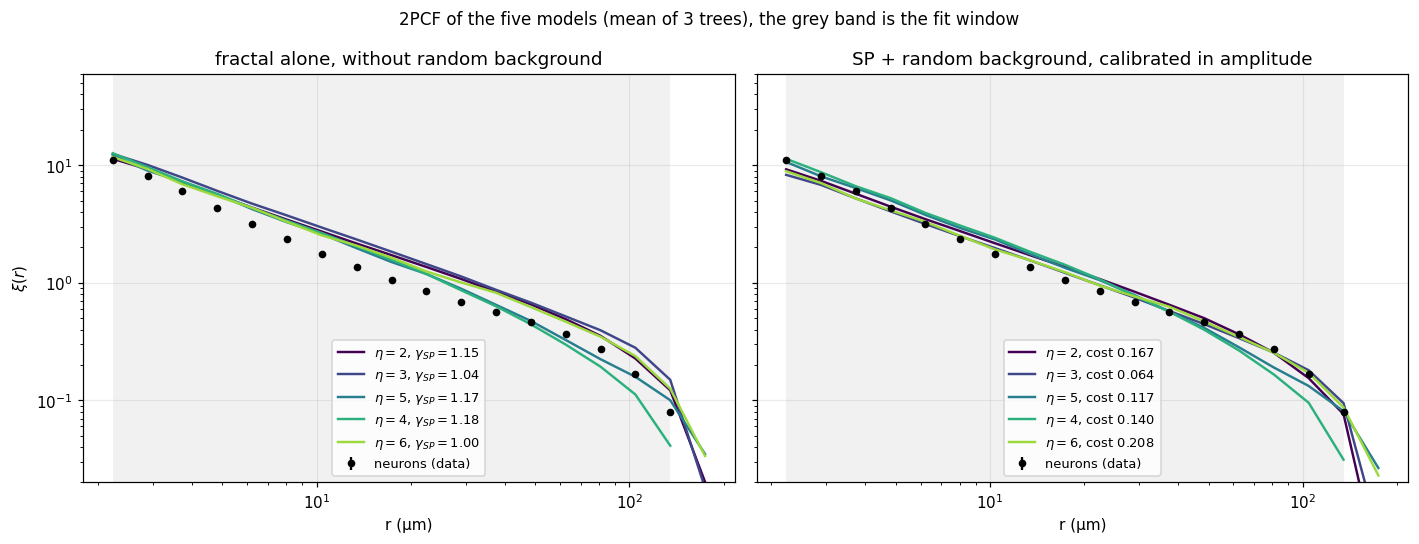

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
cols = plt.cm.viridis(np.linspace(0, .85, len(l_cluster)))

ax = axes[0]
for eta, col in zip(l_cluster, cols):
    xi_s = np.mean([SCAN[(eta, t)]["xi_sp"] for t in range(N_TRY)], axis=0)
    p = xi_s > 0
    ax.plot(r_c[p]/NM, xi_s[p], "-", color=col, lw=1.6,
            label=fr"$\eta={eta}$, $\gamma_{{SP}}={agg(eta,'gamma_sp')[0]:.2f}$")
ax.errorbar(r_c/NM, np.where(xi_data > 0, xi_data, np.nan), yerr=err_data, fmt="o",
            ms=4, color=C["data"], label="neurons (data)", zorder=5)
ax.set_title("fractal alone, without random background")

ax = axes[1]
for eta, col in zip(l_cluster, cols):
    xi_m = np.mean([SCAN[(eta, t)]["xi_mx"] for t in range(N_TRY)], axis=0)
    p = xi_m > 0
    ax.plot(r_c[p]/NM, xi_m[p], "-", color=col, lw=1.6,
            label=fr"$\eta={eta}$, cost {agg(eta,'cost')[0]:.3f}")
ax.errorbar(r_c/NM, np.where(xi_data > 0, xi_data, np.nan), yerr=err_data, fmt="o",
            ms=4, color=C["data"], label="neurons (data)", zorder=5)
ax.set_title("SP + random background, calibrated in amplitude")

for ax in axes:
    ax.axvspan(r_c[WIN][0]/NM, r_c[WIN][-1]/NM, color="0.85", alpha=.35, lw=0, zorder=0)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(2e-2, 6e1)
    ax.set_xlabel("r (µm)"); ax.legend(fontsize=8.5)
axes[0].set_ylabel(r"$\xi(r)$")
fig.suptitle("2PCF of the five models (mean of 3 trees), the grey band is the "
             "fit window", fontsize=11)
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_2pcf_scan.pdf", bbox_inches="tight")
plt.show()

## 7. Is η identifiable?

The 2PCF of an SP fractal depends on η and λ only through D, which is fixed by the
calibration. The five models differ by their lacunarity, which the 2PCF does not
measure. η changes the variance, since the first levels hold only η, η², … clusters and
a bad draw there is never corrected. η is therefore chosen for stability.

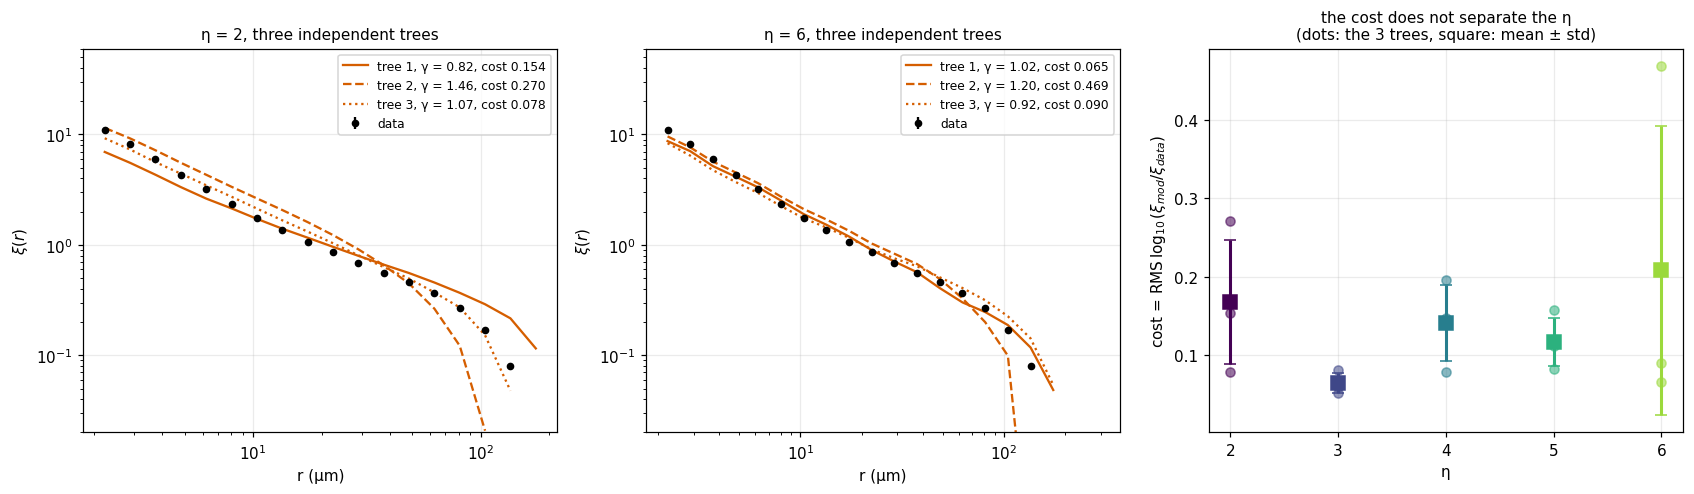

   η    mean cost          std    ρ min    ρ max   γ_mix min   γ_mix max
   2       0.1674       0.0791     0.60     1.38       0.817       1.460
   3       0.0636       0.0128     0.61     0.72       0.951       1.063
   4       0.1401       0.0485     0.80     1.09       1.060       1.382
   5       0.1167       0.0309     0.69     1.07       0.984       1.229
   6       0.2080       0.1850     0.68     0.83       0.916       1.201

gap between the best and the worst η: 0.1444   |   typical tree-to-tree dispersion: 0.0712


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))
for ax, eta in zip(axes[:2], [l_cluster[0], max(l_cluster)]):
    for t, ls in zip(range(N_TRY), ["-", "--", ":"]):
        xi_m = SCAN[(eta, t)]["xi_mx"]; p = xi_m > 0
        ax.plot(r_c[p]/NM, xi_m[p], ls, color=C["sp"], lw=1.5,
                label=f"tree {t+1}, γ = {SCAN[(eta,t)]['gamma_mx']:.2f}, "
                      f"cost {SCAN[(eta,t)]['cost']:.3f}")
    ax.errorbar(r_c/NM, np.where(xi_data > 0, xi_data, np.nan), yerr=err_data,
                fmt="o", ms=4, color=C["data"], label="data", zorder=5)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(2e-2, 6e1)
    ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
    ax.set_title(f"η = {eta}, three independent trees", fontsize=10)
    ax.legend(fontsize=8)

ax = axes[2]
for eta, col in zip(sorted(l_cluster), plt.cm.viridis(np.linspace(0, .85, len(l_cluster)))):
    cs = [SCAN[(eta, t)]["cost"] for t in range(N_TRY)]
    ax.plot([eta]*N_TRY, cs, "o", color=col, ms=6, alpha=.55)
    ax.errorbar([eta], [np.mean(cs)], yerr=[np.std(cs)], fmt="s", color=col, ms=9,
                capsize=4, lw=2)
ax.set_xlabel("η"); ax.set_ylabel(r"cost = RMS$\,\log_{10}(\xi_{mod}/\xi_{data})$")
ax.set_title("the cost does not separate the η\n(dots: the 3 trees, "
             "square: mean ± std)", fontsize=10)
ax.set_xticks(sorted(l_cluster))
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_variance.pdf", bbox_inches="tight")
plt.show()

print(f"{'η':>4}{'mean cost':>13}{'std':>13}{'ρ min':>9}{'ρ max':>9}"
      f"{'γ_mix min':>12}{'γ_mix max':>12}")
for eta in sorted(l_cluster):
    cs  = [SCAN[(eta, t)]["cost"] for t in range(N_TRY)]
    rhs = [SCAN[(eta, t)]["rho"] for t in range(N_TRY)]
    gms = [SCAN[(eta, t)]["gamma_mx"] for t in range(N_TRY)]
    print(f"{eta:>4}{np.mean(cs):>13.4f}{np.std(cs):>13.4f}{min(rhs):>9.2f}"
          f"{max(rhs):>9.2f}{min(gms):>12.3f}{max(gms):>12.3f}")
ec = [agg(e, "cost")[0] for e in l_cluster]
print(f"\ngap between the best and the worst η: {max(ec)-min(ec):.4f}"
      f"   |   typical tree-to-tree dispersion: "
      f"{np.mean([agg(e,'cost')[1] for e in l_cluster]):.4f}")

## 8. Selected model

Lowest mean cost, new tree, 2PCF measured with exactly the settings of notebook 05
(k = 8, N_run = 4 catalogues of 20 000 points, Nsample = 20 000).

In [13]:
eta_star  = min(l_cluster, key=lambda e: agg(e, "cost")[0])
frac_star = agg(eta_star, "frac")[0]

_c = CACHE / f"final_{SEED}_{eta_star}.joblib"
if _c.exists():
    FIN = joblib.load(_c)
else:
    t0 = time.time()
    g = np.random.default_rng(SEED + 999)
    S_f, lam_f, L_f = build_sp(eta_star, g)
    l_sp = xi_nd(S_f, k=4, rng=g)
    rho_f, frac_f = calibrate(l_sp.mean(axis=0))
    M_f, n_sp_f, n_rd_f = build_mixture(S_f, frac_f, g)
    l_mx = xi_nd(M_f, k=8, rng=g)                    # k = 8, as for the data
    FIN = dict(eta=eta_star, lamb=lam_f, L=L_f, n_leaves=len(S_f),
               xi_sp=l_sp.mean(axis=0), xi_sp_std=l_sp.std(axis=0),
               rho=rho_f, frac=frac_f, N_sp=n_sp_f, N_rd=n_rd_f,
               l_xi=l_mx, xi=l_mx.mean(axis=0), xi_std=l_mx.std(axis=0),
               model=M_f)
    joblib.dump(FIN, _c)
    print(f"(final model: {time.time()-t0:.0f} s)")

fit_mx = fit_pl(FIN["xi"], FIN["xi_std"])
fit_sp = fit_pl(FIN["xi_sp"], FIN["xi_sp_std"])
MODEL  = FIN["model"]
print(f"η = {FIN['eta']}   λ = {FIN['lamb']:.4f}   L = {FIN['L']}   "
      f"leaves = {FIN['n_leaves']:,}".replace(",", " "))
print(f"  lost by rejection (outside the hull): "
      f"{100*(1 - FIN['n_leaves']/FIN['eta']**FIN['L']):.1f} % of η^L")
print(f"  ρ = {FIN['rho']:.3f} → f = {FIN['frac']:.3f}: {FIN['N_sp']:,} fractal "
      f"points + {FIN['N_rd']:,} background = {len(MODEL):,}".replace(",", " "))
print(f"\n{'':<22}{'γ':>18}{'r0 (µm)':>16}{'ξ(2.2 µm)':>12}{'ξ(17 µm)':>11}")
print(f"{'data':<22}{gamma_d:>11.3f} ± {f_data['gamma_err']:.3f}"
      f"{r0_d/NM:>10.1f} ± {f_data['r0_err']/NM:.1f}{xi_data[0]:>12.2f}{xi_data[8]:>11.2f}")
print(f"{'SP + background':<22}{fit_mx['gamma']:>11.3f} ± {fit_mx['gamma_err']:.3f}"
      f"{fit_mx['r0']/NM:>10.1f} ± {fit_mx['r0_err']/NM:.1f}"
      f"{FIN['xi'][0]:>12.2f}{FIN['xi'][8]:>11.2f}")
print(f"{'fractal alone':<22}{fit_sp['gamma']:>11.3f} ± {fit_sp['gamma_err']:.3f}"
      f"{fit_sp['r0']/NM:>10.1f} ± {fit_sp['r0_err']/NM:.1f}"
      f"{FIN['xi_sp'][0]:>12.2f}{FIN['xi_sp'][8]:>11.2f}")
sel = WIN & (FIN["xi"] > 0) & (xi_data > 0)
print(f"\ngap |ξ_mod/ξ_data − 1| on the window: median "
      f"{100*np.median(np.abs(FIN['xi'][sel]/xi_data[sel] - 1)):.0f} %, "
      f"max {100*np.max(np.abs(FIN['xi'][sel]/xi_data[sel] - 1)):.0f} %")

η = 3   λ = 1.7429   L = 12   leaves = 531 441
  lost by rejection (outside the hull): 0.0 % of η^L
  ρ = 0.658 → f = 0.811: 193 783 fractal points + 45 126 background = 238 909

                                       γ         r0 (µm)   ξ(2.2 µm)   ξ(17 µm)
data                        1.022 ± 0.036      19.5 ± 0.7       11.05       1.06
SP + background             0.955 ± 0.009      20.2 ± 0.2        8.05       1.17
fractal alone               0.949 ± 0.008      31.5 ± 0.4       12.04       1.76

gap |ξ_mod/ξ_data − 1| on the window: median 8 %, max 80 %


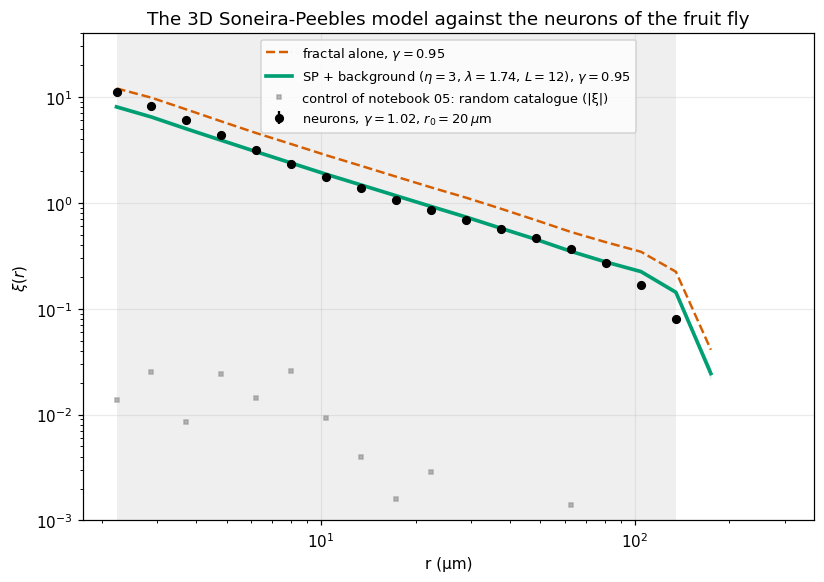

In [14]:
fig, ax = plt.subplots(figsize=(7.6, 5.4))
ax.axvspan(r_c[WIN][0]/NM, r_c[WIN][-1]/NM, color="0.88", alpha=.5, lw=0, zorder=0)
ax.errorbar(r_c/NM, np.where(xi_data > 0, xi_data, np.nan), yerr=err_data, fmt="o",
            ms=5, color=C["data"], zorder=6,
            label=fr"neurons, $\gamma={gamma_d:.2f}$, $r_0={r0_d/NM:.0f}\,\mu$m")
p = FIN["xi_sp"] > 0
ax.plot(r_c[p]/NM, FIN["xi_sp"][p], "--", color=C["sp"], lw=1.6,
        label=fr"fractal alone, $\gamma={fit_sp['gamma']:.2f}$")
p = FIN["xi"] > 0
ax.plot(r_c[p]/NM, FIN["xi"][p], "-", color=C["mix"], lw=2.4, zorder=5,
        label=fr"SP + background ($\eta={FIN['eta']}$, $\lambda={FIN['lamb']:.2f}$, "
              fr"$L={FIN['L']}$), $\gamma={fit_mx['gamma']:.2f}$")
ax.fill_between(r_c[p]/NM, np.clip(FIN["xi"] - FIN["xi_std"], 1e-3, None)[p],
                (FIN["xi"] + FIN["xi_std"])[p], color=C["mix"], alpha=.18, lw=0)
ax.plot(r_c/NM, np.abs(d["xi_random"]), "s", ms=3, color=C["random"], alpha=.7,
        label="control of notebook 05: random catalogue (|ξ|)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-3, 4e1)
ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("The 3D Soneira-Peebles model against the neurons of the fruit fly")
ax.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_2pcf.pdf", bbox_inches="tight")
plt.show()

## 9. Kullback-Leibler divergence of the distances

The 2PCF was used for the calibration, so we also compare the distributions of pairwise
distances, D_KL(P‖Q) = Σ P ln(P/Q), with P the neurons (50 000 points, notebook 05) and
Q the model (30 000 points). The value is compared with the one of a uniform catalogue
in the same hull.

In [15]:
N_KL, N_UNI, n_kl = 8, 8, 30_000

def pdist_hist(P, rng, n=n_kl):
    """Normalised pairwise distance distribution, on the bins of the data."""
    sub = P if len(P) <= n else P[rng.choice(len(P), n, replace=False)]
    h = mtpc.pair_counts(sub, r_edges).astype(float)
    return h / h.sum()

def kl_div(p, q, eps=1e-12):
    q = np.clip(q, eps, None); m = p > 0
    return float(np.sum(p[m] * np.log(p[m] / q[m])))

P_data = d["distance_distribution"] / d["distance_distribution"].sum()

_c = CACHE / f"kl_{SEED}_{eta_star}.joblib"
if _c.exists():
    KL = joblib.load(_c)
else:
    t0 = time.time()
    kl_mod, kl_uni, H_mod, H_uni = [], [], [], []
    for i in range(N_KL):
        g = np.random.default_rng(SEED + 7000 + i)
        S_i, _, _ = build_sp(eta_star, g)
        M_i, _, _ = build_mixture(S_i, FIN["frac"], g)
        h = pdist_hist(M_i, g); H_mod.append(h); kl_mod.append(kl_div(P_data, h))
    for i in range(N_UNI):
        g = np.random.default_rng(SEED + 8000 + i)
        h = pdist_hist(mtpc.sample_in_hull(hull, n_kl, g), g)
        H_uni.append(h); kl_uni.append(kl_div(P_data, h))
    KL = dict(mod=np.array(kl_mod), uni=np.array(kl_uni),
              H_mod=np.array(H_mod), H_uni=np.array(H_uni))
    joblib.dump(KL, _c)
    print(f"(KL: {N_KL + N_UNI} catalogues in {time.time()-t0:.0f} s)")

print(f"D_KL(neurons ‖ SP + background) = {KL['mod'].mean():.4f} ± {KL['mod'].std():.4f}")
print(f"D_KL(neurons ‖ uniform)         = {KL['uni'].mean():.4f} ± {KL['uni'].std():.4f}")
print(f"gain of the model: factor {KL['uni'].mean()/KL['mod'].mean():.2f} "
      f"({100*(1 - KL['mod'].mean()/KL['uni'].mean()):.0f} % of the divergence "
      f"to the null is explained)")

D_KL(neurons ‖ SP + background) = 0.0108 ± 0.0056
D_KL(neurons ‖ uniform)         = 0.0340 ± 0.0003
gain of the model: factor 3.14 (68 % of the divergence to the null is explained)


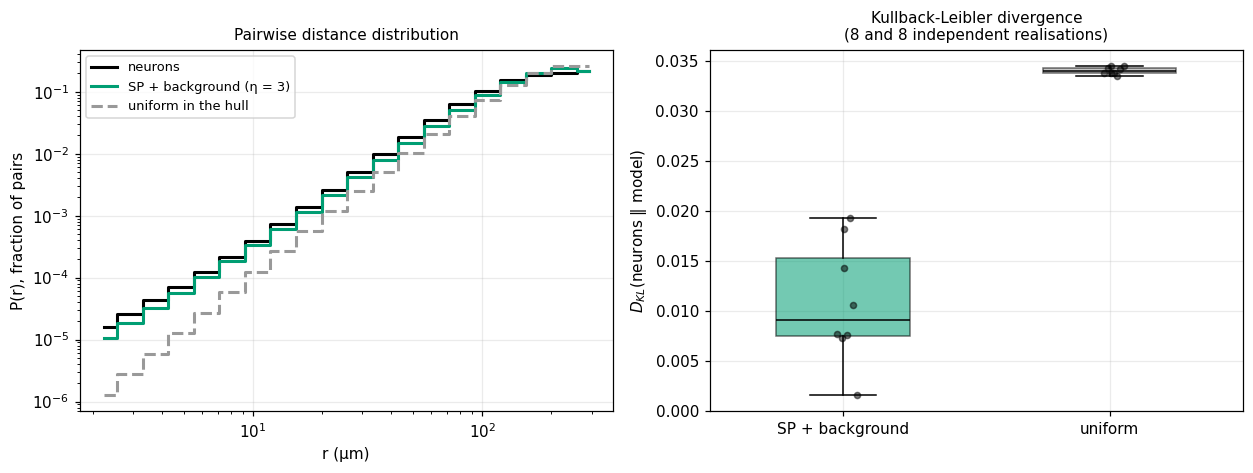

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

ax = axes[0]
ax.step(r_c/NM, P_data, where="mid", color=C["data"], lw=2, label="neurons")
ax.step(r_c/NM, KL["H_mod"].mean(axis=0), where="mid", color=C["mix"], lw=2,
        label=f"SP + background (η = {eta_star})")
ax.step(r_c/NM, KL["H_uni"].mean(axis=0), where="mid", color=C["random"], lw=2,
        ls="--", label="uniform in the hull")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel("P(r), fraction of pairs")
ax.set_title("Pairwise distance distribution", fontsize=10)
ax.legend(fontsize=8.5)

ax = axes[1]
bp = ax.boxplot([KL["mod"], KL["uni"]], labels=["SP + background", "uniform"],
                widths=.5, patch_artist=True, medianprops=dict(color="k"))
for patch, col in zip(bp["boxes"], [C["mix"], C["random"]]):
    patch.set_facecolor(col); patch.set_alpha(.55)
for x, v in zip([1, 2], [KL["mod"], KL["uni"]]):
    ax.plot(np.full(len(v), x) + np.random.default_rng(0).normal(0, .04, len(v)),
            v, "o", ms=4, color="k", alpha=.5)
ax.set_ylabel(r"$D_{KL}$(neurons $\Vert$ model)")
ax.set_title(f"Kullback-Leibler divergence\n"
             f"({N_KL} and {N_UNI} independent realisations)", fontsize=10)
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_kl.pdf", bbox_inches="tight")
plt.show()

## 10. Visual comparison

Same number of displayed points, three projections.

In [17]:
DATA = ROOT / "data" / "fly_neuron_net" / "neurons.zip"
gdf  = mtpc.load_points_3d(DATA)
X    = mtpc.coords_3d(gdf)
print(f"{len(X):,} neurons loaded  |  model: {len(MODEL):,} points"
      .replace(",", " "))

238 909 neurons loaded  |  model: 238 909 points


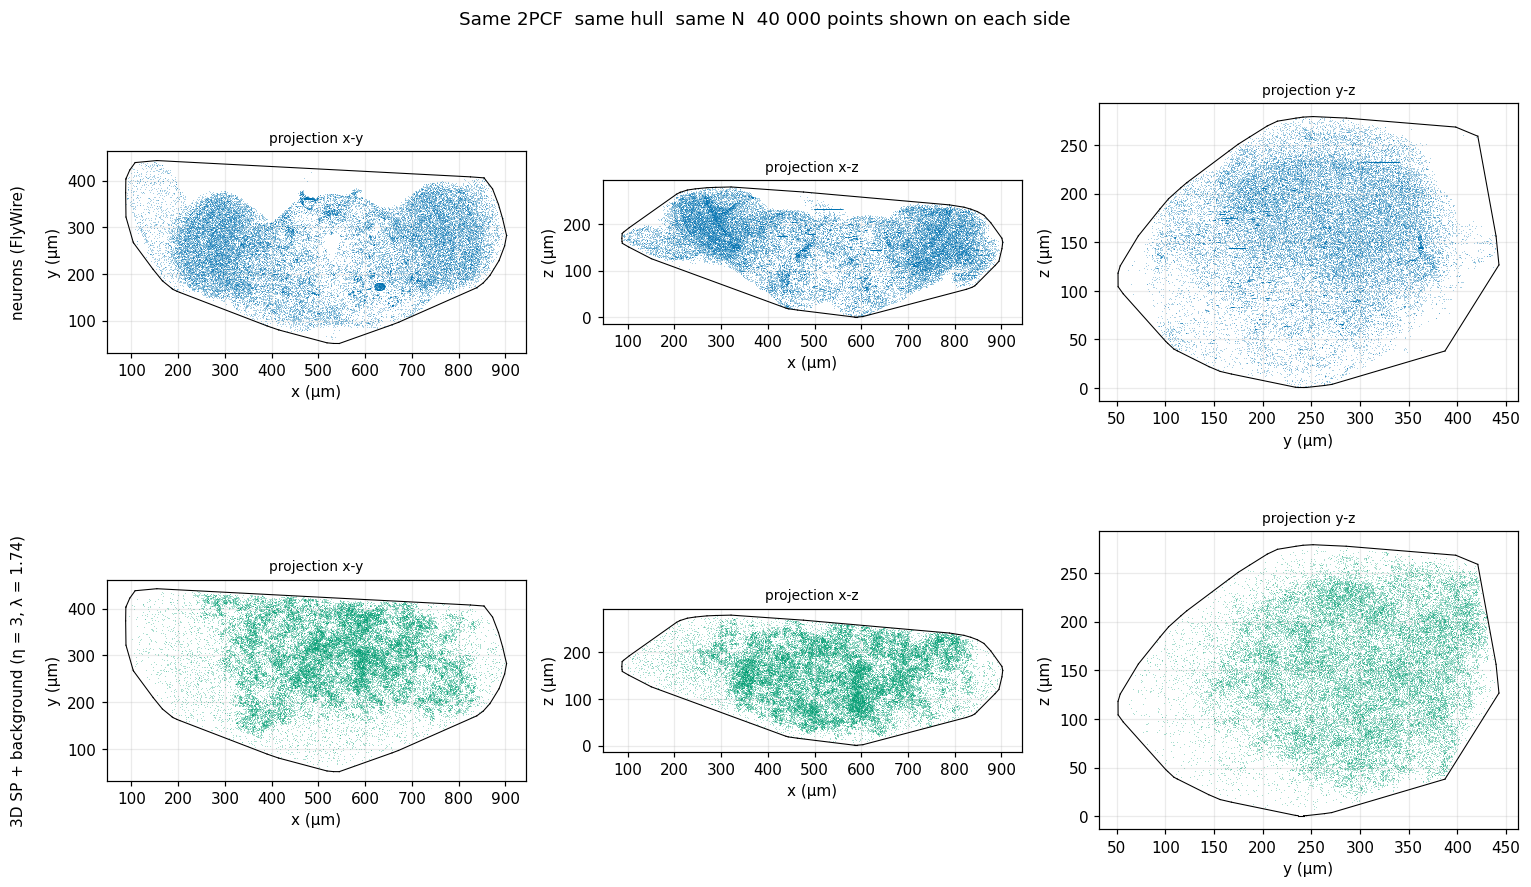

In [18]:
g_v = np.random.default_rng(SEED)
n_v = 40_000
sub_d = X[g_v.choice(len(X), n_v, replace=False)]
sub_m = MODEL[g_v.choice(len(MODEL), n_v, replace=False)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8.4))
for row, (P, col, name) in enumerate([(sub_d, C["fly"], "neurons (FlyWire)"),
                                      (sub_m, C["mix"], f"3D SP + background "
                                       f"(η = {eta_star}, λ = {FIN['lamb']:.2f})")]):
    for ax, (i, j), lbl in zip(axes[row], [(0, 1), (0, 2), (1, 2)],
                               ["x-y", "x-z", "y-z"]):
        ax.scatter(P[:, i]/NM, P[:, j]/NM, s=.4, alpha=.25, color=col, lw=0,
                   rasterized=True)
        for s in ConvexHull(hull.points[:, [i, j]]).simplices:
            ax.plot(hull.points[s, i]/NM, hull.points[s, j]/NM, color="k", lw=.7)
        ax.set_xlabel(f"{lbl[0]} (µm)"); ax.set_ylabel(f"{lbl[-1]} (µm)")
        ax.set_aspect("equal")
        if ax is axes[row][0]:
            ax.set_ylabel(f"{name}\n\n{lbl[-1]} (µm)")
        ax.set_title(f"projection {lbl}", fontsize=9)
fig.suptitle("Same 2PCF, same hull, same N, "
             f"{n_v:,}".replace(",", " ") + " points shown on each side")
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_visual.pdf", bbox_inches="tight", dpi=200)
plt.show()

The model does not fill the hull like the brain. The neurons form two lobes with a
central gap, the SP is concentrated at the centre. A child of level i lies within
R/(λ−1) of the seed, so the density of the model decreases radially, and the rejection
at the hull makes it worse. The two clouds share γ within 7 % and r₀ within 4 %.

## 11. What the model does not reproduce

1. **Cell size.** The nearest-neighbour distance of the neurons has a mode at 3.6 µm
   (plus 13 321 duplicated positions, 5.6 %). The SP has no exclusion between points.
2. **Position of the clusters.** Distance from each model point to the nearest real
   neuron, compared with a uniform catalogue.
3. **Bilateral symmetry.** The x profile of the neurons is bimodal, an SP is isotropic
   around its seed.

In [19]:
g_l   = np.random.default_rng(SEED + 3)
n_l   = 60_000
i_d   = g_l.choice(len(X), n_l, replace=False)
i_m   = g_l.choice(len(MODEL), n_l, replace=False)
U_l   = mtpc.sample_in_hull(hull, n_l, g_l)

nn = {}
for name, P in [("neurons", X[i_d]), ("SP + background", MODEL[i_m]), ("uniform", U_l)]:
    nn[name] = cKDTree(P).query(P, k=2, workers=-1)[0][:, 1]

T_data = cKDTree(X)
d_mod  = T_data.query(MODEL[i_m], workers=-1)[0]
d_uni  = T_data.query(U_l,        workers=-1)[0]
THRESH = 10 * NM
frac_mod = float((d_mod > THRESH).mean())
frac_uni = float((d_uni > THRESH).mean())

print(f"duplicated positions in the data: "
      f"{int(pd.DataFrame(X).duplicated().sum()):,} "
      f"({100*pd.DataFrame(X).duplicated().mean():.1f} %)\n".replace(",", " "))
print(f"{'':<17}{'median d_nn (µm)':>18}{'mode (µm)':>12}{'1st percentile (µm)':>21}")
be_m = np.logspace(np.log10(.05*NM), np.log10(30*NM), 60)
c_m  = np.sqrt(be_m[:-1] * be_m[1:])
for name, v in nn.items():
    mode = c_m[np.histogram(v, bins=be_m)[0].argmax()]
    print(f"{name:<17}{np.median(v)/NM:>18.2f}{mode/NM:>12.2f}"
          f"{np.percentile(v, 1)/NM:>21.3f}")
print(f"\n(subsampling to {n_l:,} points stretches these distances by a "
      f"factor ~({len(X)/n_l:.1f})^(1/3) = {(len(X)/n_l)**(1/3):.2f}, "
      f"only the comparison between rows matters)".replace(",", " "))
print(f"\npoints more than {THRESH/NM:.0f} µm away from any real neuron: "
      f"model {100*frac_mod:.1f} %  |  uniform {100*frac_uni:.1f} %")
print(f"median distance to the nearest real neuron: "
      f"model {np.median(d_mod)/NM:.2f} µm  |  uniform {np.median(d_uni)/NM:.2f} µm")

duplicated positions in the data: 13 321 (5.6 %)

                   median d_nn (µm)   mode (µm)  1st percentile (µm)
neurons                        3.11        3.62                0.000
SP + background                2.14        2.11                0.364
uniform                        4.79        5.59                1.166

(subsampling to 60 000 points stretches these distances by a factor ~(4.0)^(1/3) = 1.58  only the comparison between rows matters)

points more than 10 µm away from any real neuron: model 30.0 %  |  uniform 27.8 %
median distance to the nearest real neuron: model 5.35 µm  |  uniform 4.95 µm


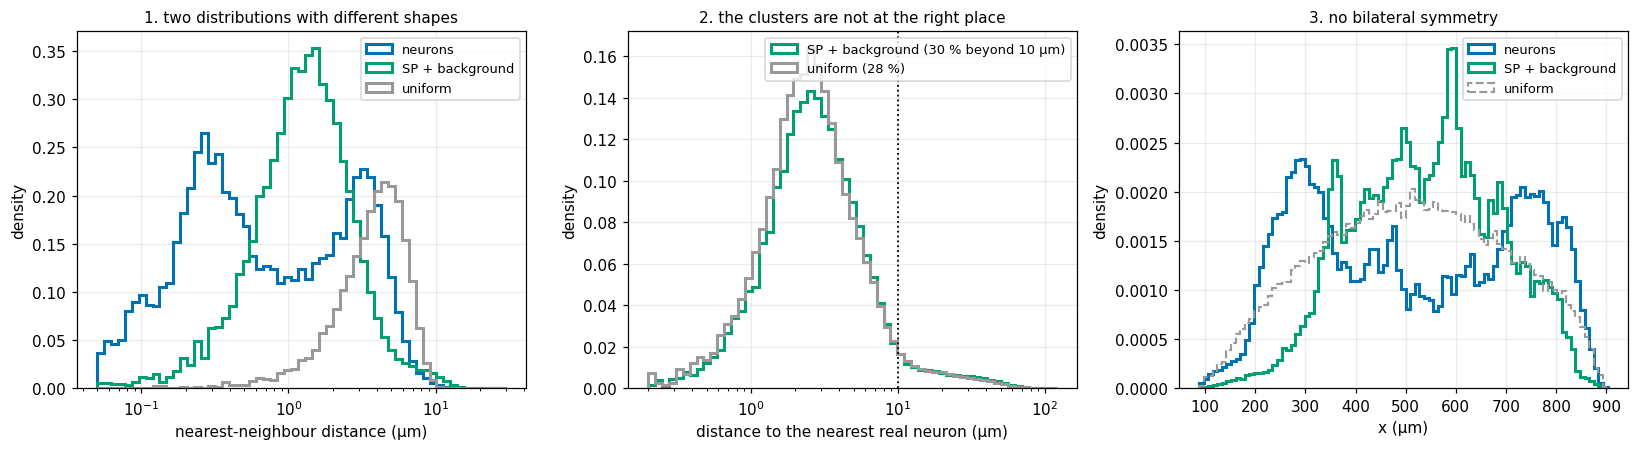

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
be = np.logspace(np.log10(.05), np.log10(30), 60)
for (name, v), col in zip(nn.items(), [C["fly"], C["mix"], C["random"]]):
    ax.hist(v/NM, bins=be, histtype="step", lw=2, density=True, color=col, label=name)
ax.set_xscale("log"); ax.set_xlabel("nearest-neighbour distance (µm)")
ax.set_ylabel("density"); ax.legend(fontsize=8.5)
ax.set_title("1. two distributions with different shapes", fontsize=10)

ax = axes[1]
be2 = np.logspace(np.log10(.2), np.log10(120), 60)
ax.hist(d_mod/NM, bins=be2, histtype="step", lw=2, density=True, color=C["mix"],
        label=f"SP + background ({100*frac_mod:.0f} % beyond 10 µm)")
ax.hist(d_uni/NM, bins=be2, histtype="step", lw=2, density=True, color=C["random"],
        label=f"uniform ({100*frac_uni:.0f} %)")
ax.axvline(THRESH/NM, color="k", ls=":", lw=1.2)
ax.set_xscale("log"); ax.set_xlabel("distance to the nearest real neuron (µm)")
ax.set_ylabel("density"); ax.legend(fontsize=8.5)
ax.set_title("2. the clusters are not at the right place", fontsize=10)

ax = axes[2]
bx = np.linspace(X[:, 0].min()/NM, X[:, 0].max()/NM, 90)
ax.hist(X[:, 0]/NM, bins=bx, histtype="step", lw=2, density=True, color=C["fly"],
        label="neurons")
ax.hist(MODEL[:, 0]/NM, bins=bx, histtype="step", lw=2, density=True, color=C["mix"],
        label="SP + background")
ax.hist(U_l[:, 0]/NM, bins=bx, histtype="step", lw=1.4, ls="--", density=True,
        color=C["random"], label="uniform")
ax.set_xlabel("x (µm)"); ax.set_ylabel("density"); ax.legend(fontsize=8.5)
ax.set_title("3. no bilateral symmetry", fontsize=10)

fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_limits.pdf", bbox_inches="tight")
plt.show()

## 12. Saving

In [21]:
out_dir = ROOT / "out" / "fly"
out_dir.mkdir(parents=True, exist_ok=True)

scan_tab = pd.DataFrame([
    dict(eta=eta, trial=t, lamb=SCAN[(eta, t)]["lamb"], L=SCAN[(eta, t)]["L"],
         n_leaves=SCAN[(eta, t)]["n_leaves"],
         r_bot_um=SCAN[(eta, t)]["r_bot"]/NM,
         gamma_sp=SCAN[(eta, t)]["gamma_sp"], rho=SCAN[(eta, t)]["rho"],
         frac=SCAN[(eta, t)]["frac"], gamma_mix=SCAN[(eta, t)]["gamma_mx"],
         cost_log=SCAN[(eta, t)]["cost"], cost_eucl=SCAN[(eta, t)]["cost_eucl"])
    for eta in l_cluster for t in range(N_TRY)])

xi_tab = pd.DataFrame({
    "r_nm": r_c, "r_um": r_c/NM, "in_fit_window": WIN,
    "xi_data": xi_data, "xi_data_std": err_data,
    "xi_sp": FIN["xi_sp"], "xi_sp_std": FIN["xi_sp_std"],
    "xi_mix": FIN["xi"], "xi_mix_std": FIN["xi_std"],
    "P_data": P_data, "P_mix": KL["H_mod"].mean(axis=0),
    "P_uniform": KL["H_uni"].mean(axis=0)})

d_save = {
    "r_edges": r_edges, "r_centers": r_c,
    "xi": FIN["l_xi"],                       # (8, nbins), same shape as in notebook 05
    "xi_data": d["xi"], "xi_sp": FIN["xi_sp"],
    "fit_SP": (fit_mx["gamma"], fit_mx["r0"]),
    "fit_data": (gamma_d, r0_d),
    "model_points": MODEL,
    "sp_params": dict(eta=int(eta_star), lamb=FIN["lamb"], L=int(FIN["L"]),
                      R_ref=R_ref, center=cen, radial="uniform",
                      n_leaves=int(FIN["n_leaves"]), rho=FIN["rho"],
                      frac=FIN["frac"], N_sp=int(FIN["N_sp"]),
                      N_rd=int(FIN["N_rd"]), D=3 - gamma_d),
    "scan": scan_tab.to_dict("list"),
    "kl": dict(model=KL["mod"], uniform=KL["uni"]),
    "number_points": len(MODEL), "dim": 3,
    "hull_points": d["hull_points"],
    "params": dict(prm, seed=SEED, fit_hi=FIT_HI, N_TRY=N_TRY,
                   source=str(PKL.name)),
}
pkl_out = out_dir / f"fly_sp3d_{eta_star}_{FIN['L']}_{N_TRY}_{prm['nbins']}"
slp.save_results(pkl_out, d_save)
print("->", pkl_out)

scan_tab.to_csv(ROOT / "out" / "05bis_fly_sp3d_scan.csv", index=False)
xi_tab.to_csv(ROOT / "out" / "05bis_fly_sp3d.csv", index=False)
print("->", ROOT / "out" / "05bis_fly_sp3d_scan.csv")
print("->", ROOT / "out" / "05bis_fly_sp3d.csv")

summary = pd.DataFrame([
    dict(quantity="γ", data=gamma_d, model=fit_mx["gamma"],
         fractal_only=fit_sp["gamma"]),
    dict(quantity="r0 (µm)", data=r0_d/NM, model=fit_mx["r0"]/NM,
         fractal_only=fit_sp["r0"]/NM),
    dict(quantity="D = 3 - γ", data=3 - gamma_d, model=3 - fit_mx["gamma"],
         fractal_only=3 - fit_sp["gamma"]),
    dict(quantity="ξ(2.2 µm)", data=xi_data[0], model=FIN["xi"][0],
         fractal_only=FIN["xi_sp"][0]),
    dict(quantity="D_KL vs neurons", data=0.0, model=KL["mod"].mean(),
         fractal_only=np.nan),
])
summary.to_csv(ROOT / "out" / "05bis_fly_sp3d_summary.csv", index=False)
print()
print(summary.round(3).to_string(index=False))

-> out/fly/fly_sp3d_3_12_3_21
-> out/05bis_fly_sp3d_scan.csv
-> out/05bis_fly_sp3d.csv

       quantity   data  model  fractal_only
              γ  1.022  0.955         0.949
        r0 (µm) 19.522 20.232        31.460
      D = 3 - γ  1.978  2.045         2.051
      ξ(2.2 µm) 11.050  8.054        12.042
D_KL vs neurons  0.000  0.011           NaN


## Results

| | γ | r₀ (µm) | ξ(2.2 µm) |
|---|---|---|---|
| neurons | 1.022 ± 0.036 | 19.5 | 11.05 |
| SP + background (η = 3) | 0.955 ± 0.009 | 20.2 | 8.05 |
| fractal alone | 0.949 ± 0.008 | 31.5 | 12.04 |

- Selected model: η = 3, λ = 1.743, L = 12 (531 441 leaves), 193 783 fractal points
  (f = 0.81) and 45 126 background points. The slope gap is 1.8σ of the data error, and
  ξ differs by 8 % (median over the 17 fitted bins).
- The 3D formula for λ sets the dimension (D measured on the bare trees: 1.89 to 1.98
  for a target of 1.98). The radial law leaves D unchanged and multiplies ξ(2.2 µm) by
  2.2 when `r = R·u` is used. Child-by-child rejection is needed, since 92 % of the
  level-1 children fall outside the hull.
- η is not identifiable from ξ. The cost gap between the best (η = 3, 0.064 ± 0.013)
  and worst (η = 6, 0.208) candidate is 0.14, for a tree-to-tree spread of 0.07.
  η = 2 and η = 6 are unstable between trees, η = 3 is the most stable.
- D_KL of the distances: 0.011 ± 0.006 for the model, 0.034 for the uniform catalogue,
  so the model removes 68 % of the divergence to the null.
- The model does not locate the neurons. 30.0 % of its points are more than 10 µm from
  any neuron (27.8 % for a uniform catalogue). Its nearest-neighbour mode is at 2.1 µm
  instead of 3.6 µm, and its x profile is unimodal.